In [1]:
import torch
from torch import nn

In [28]:
# Load the FashionMNIST dataset
import torchvision
import torchvision.transforms as transforms 

# Create a set of transforms to apply to the images
# a. Convert the images to PyTorch tensors
# b. Pad the 28x28 images to 32x32

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Pad(2, fill=0.0),
])

trainset = torchvision.datasets.FashionMNIST(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.FashionMNIST(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64,
                                         shuffle=False, num_workers=2)

In [29]:
## Create a sampling layer for the VAE

class SamplingLayer(nn.Module):
    def __init__(self):
        super(SamplingLayer, self).__init__()

    def forward(self, mu, log_var):
        """Reparameterization trick to sample from N(mu, var) from N(0,1).
        
        Args:
            mu: Mean of the latent Gaussian [B, D]
            log_var: Log variance of the latent Gaussian [B, D]
        """
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

In [30]:
# Create the encoder of the VAE

class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super(Encoder, self).__init__()
        self.latent_dim = latent_dim
        self.conv1 = nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1)  # [B, 1, 32, 32] -> [B, 32, 16, 16]
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1) # [B, 64, 8, 8]
        self.conv3 = nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1) # [B, 128, 4, 4]
        self.fc_mu = nn.Linear(128*4*4, latent_dim)  # Mean vector [B, latent_dim]
        self.fc_logvar = nn.Linear(128*4*4, latent_dim) # Log variance vector [B, latent_dim]
        self.relu = nn.ReLU()
        self.sampling = SamplingLayer()

    def forward(self, x):
        x = self.relu(self.conv1(x)) # [B, 32, 16, 16]
        x = self.relu(self.conv2(x)) # [B, 64, 8, 8]
        x = self.relu(self.conv3(x)) # [B, 128, 4, 4]
        x = x.view(x.size(0), -1)
        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        z = self.sampling(mu, logvar)
        return z, mu, logvar

In [31]:
# Create the decoder of the VAE

class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super(Decoder, self).__init__()
        self.fc = nn.Linear(latent_dim, 128*4*4)
        self.deconv1 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1) # [B, 64, 8, 8]
        self.deconv2 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1)  # [B, 32, 16, 16]
        self.deconv3 = nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1)   # [B, 1, 32, 32]
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, z):
        x = self.fc(z)
        x = x.view(x.size(0), 128, 4, 4)
        x = self.relu(self.deconv1(x))
        x = self.relu(self.deconv2(x))
        x = self.sigmoid(self.deconv3(x))
        return x

In [32]:
## Define the VAE model

class VAE(nn.Module):
    def __init__(self, latent_dim):
        super(VAE, self).__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        z, mu, logvar = self.encoder(x)
        reconstructed_x = self.decoder(z)
        return reconstructed_x, mu, logvar

In [47]:
## Train the VAE model on the FashionMNIST dataset
import torch.optim as optim
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 2

model = VAE(latent_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Define the loss function
# 1. Reconstruction loss (`MSELoss`)
reconstruction_loss_fn = nn.MSELoss(reduction='mean')

# 2. KL Divergence loss (Mean over the batch)
def kl_divergence(mu, logvar):
    return torch.mean(-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))

# Training loop

num_epochs = 5
beta = 100.0  # Weight for Reconstruction Loss

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for batch_idx, (images, _) in enumerate(trainloader):
        images = images.to(device)
        batch_size = images.size(0)
        optimizer.zero_grad()
        reconstructed_batch, mu, logvar = model(images)
        recon_loss = reconstruction_loss_fn(reconstructed_batch, images)
        kl_loss = kl_divergence(mu, logvar)
        loss = beta * recon_loss + kl_loss
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
    print(f'Epoch {epoch+1}, Loss: {train_loss / len(trainloader.dataset):.4f}')

Epoch 1, Loss: 0.0890
Epoch 2, Loss: 0.0839
Epoch 3, Loss: 0.0837
Epoch 4, Loss: 0.0832
Epoch 5, Loss: 0.0830


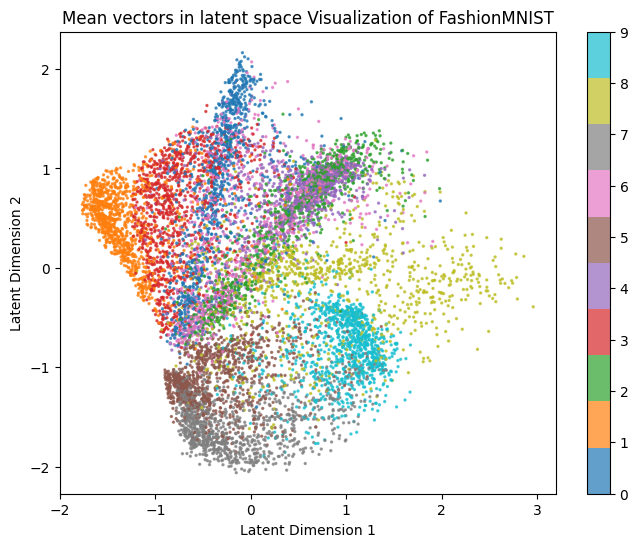

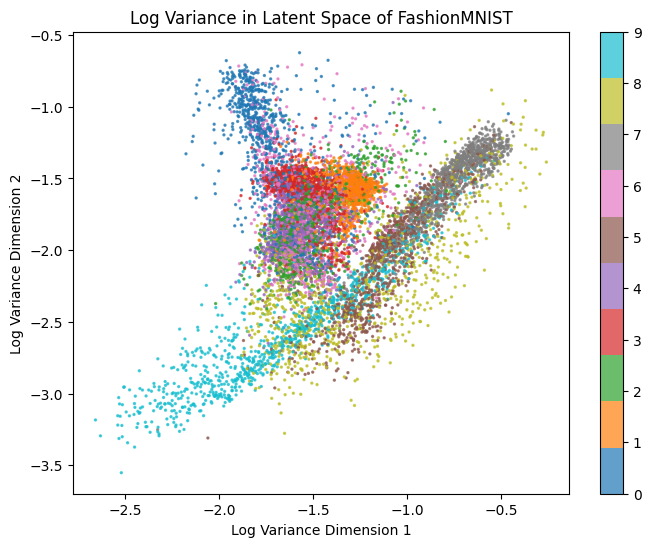

In [49]:
## Latent Space Visualization
import numpy as np
import matplotlib.pyplot as plt

latents = []
mean_vectors = []
logvar_vectors = []
labels_list = []

for images, labels in testloader:
    images = images.to(device)
    with torch.no_grad():
        latent_vectors, mu, log_var = model.encoder(images)
        latents.append(latent_vectors.cpu().numpy())
        mean_vectors.append(mu.cpu().numpy())
        logvar_vectors.append(log_var.cpu().numpy())
        labels_list.append(labels.numpy())

latents = np.concatenate(latents, axis=0)
mean_vectors = np.concatenate(mean_vectors, axis=0)
logvar_vectors = np.concatenate(logvar_vectors, axis=0)
labels_list = np.concatenate(labels_list, axis=0)

# Plot the mean vectors in latent space
plt.figure(figsize=(8, 6))
scatter = plt.scatter(mean_vectors[:, 0], mean_vectors[:, 1], c=labels_list, cmap='tab10', alpha=0.7, s=2)
plt.colorbar(scatter, ticks=range(10))
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.title('Mean vectors in latent space Visualization of FashionMNIST')
plt.show()

# Plot the log variance vectors in latent space
plt.figure(figsize=(8, 6))
scatter = plt.scatter(logvar_vectors[:, 0], logvar_vectors[:, 1], c=labels_list, cmap='tab10', alpha=0.7, s=2)
plt.colorbar(scatter, ticks=range(10))
plt.xlabel('Log Variance Dimension 1')
plt.ylabel('Log Variance Dimension 2')
plt.title('Log Variance in Latent Space of FashionMNIST')
plt.show()

# Get the unique set of labels
unique_labels = np.unique(labels_list)

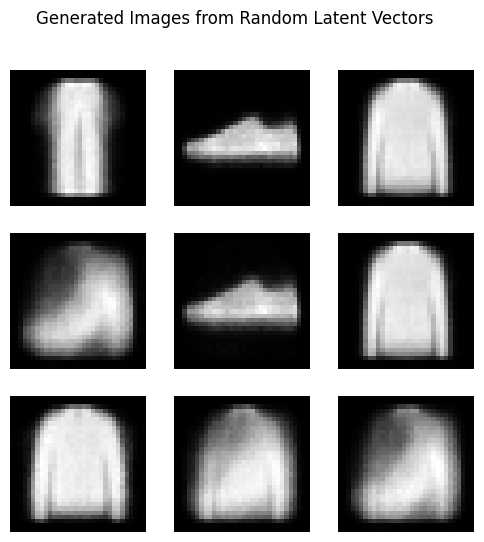

In [50]:
## Generate new images by sampling from the latent space
num_images = 9

fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i in range(num_images):
    # Sample a random latent vector from a standard normal distribution
    z = torch.randn(1, latent_dim).to(device)
    with torch.no_grad():
        generated_image = model.decoder(z)
    ax = axes[i // 3, i % 3]
    ax.imshow(generated_image.squeeze().cpu(), cmap='gray')
    ax.axis('off')
plt.suptitle('Generated Images from Random Latent Vectors')
plt.show()

In [46]:
mu_t = torch.randn(16, 8)
logvar_t = torch.randn(16, 8)

# KL Divergence calculation
kl_loss = kl_divergence(mu_t, logvar_t)
print(" KL loss shape", kl_loss.shape)
print(f'KL Divergence Loss: {kl_loss.item():.4f}')

 KL loss shape torch.Size([])
KL Divergence Loss: 0.7855


In [6]:
# Testing out BCE Loss
import torch
from torch import nn

output = 0.25 * torch.ones((4, 3))
target = 0.5 * torch.ones((4, 3))

bce_loss_fn = nn.BCELoss(reduction='mean')
bce_loss = bce_loss_fn(output, target)
print(f'BCE Loss: {bce_loss.item():.4f}')

BCE Loss: 0.8370
